# Local incidence angle
Computes the NISAR local incidence angle (LIA) for the study box from the LOS vectors of one GSLC granule and a 10 m DEM. Change `TRACK`/`FRAME` to run another track.

In [6]:
import logging
import sys

import matplotlib.pyplot as plt
import xarray as xr
import rioxarray

sys.path.append('..')
from scripts.lia import compute_lia

logging.basicConfig(level=logging.INFO)

# Box bounds taken from data/dem/dem_10m_testbox.tif
X, Y, CRS = (315360, 325600), (4306900, 4321100), 'EPSG:32613'
TRACK, FRAME = 19, 21

In [13]:
(x1, y1, x2, y2) = xr.open_zarr('/bsuhome/julialober/nisar_snow_coherence/data/nisar/zarrs/all_pairs/track019/gunw_20m.zarr').rio.bounds()
print(x1, x2, y1, y2)

315040.0 349680.0 4279120.0 4324400.0


Needs Earthdata credentials. The DEM and the LIA GeoTIFF are skipped if they already exist, and the LIA goes to `data/lia`.

In [21]:
TRACK, FRAME = 19, 21
lia_path = compute_lia(
    (x1, x2), (y1, y2), CRS, TRACK, FRAME,
    start_date='2026-01-01', end_date='2026-11-01',
    resolution=10, out_dir='../data/lia', dem_path='../data/dem/dem_10m_fullbasin.tif',
)
lia_path

INFO:scripts.dem:DEM exists, skipping download: ../data/dem/dem_10m_fullbasin.tif
INFO:scripts.download:Searching ASF for NISAR GSLC granules: track=19, frame=21, 2026-01-01–2026-11-01
INFO:asf_search:SEARCH: Using search opts {
    "frame": [
        21
    ],
    "processingLevel": [
        "GSLC"
    ],
    "relativeOrbit": [
        19
    ],
    "start": "2026-01-01T00:00:00Z",
    "end": "2026-11-01T00:00:00Z",
    "dataset": [
        "NISAR"
    ]
}
INFO:asf_search:SEARCH: Using cmr endpoint: "https://cmr.earthdata.nasa.gov/search/granules.umm_json"
INFO:asf_search:SUBQUERY 1: Beginning subquery with opts: {
    "frame": [
        21
    ],
    "processingLevel": [
        "GSLC"
    ],
    "relativeOrbit": [
        19
    ],
    "start": "2026-01-01T00:00:00Z",
    "end": "2026-11-01T00:00:00Z",
    "collections": [
        "C1256524081-ASFDEV",
        "C1256533420-ASFDEV",
        "C1256535568-ASFDEV",
        "C1256535570-ASFDEV",
        "C1256574227-ASFDEV",
        "C1

PosixPath('../data/lia/lia_track019_frame021_10m.tif')

In [15]:
TRACK, FRAME = 128, 69
lia_path = compute_lia(
    (x1, x2), (y1, y2), CRS, TRACK, FRAME,
    start_date='2026-01-01', end_date='2026-11-01',
    resolution=10, out_dir='../data/lia', dem_path='../data/dem/dem_10m_track128_frame069.tif',
)
lia_path

INFO:rasterio.session:boto3 not available, falling back to a DummySession.
INFO:scripts.dem:Wrote DEM: ../data/dem/dem_10m_track128_frame069.tif
INFO:scripts.download:Searching ASF for NISAR GSLC granules: track=128, frame=69, 2026-01-01–2026-11-01
INFO:asf_search:SEARCH: Using search opts {
    "frame": [
        69
    ],
    "processingLevel": [
        "GSLC"
    ],
    "relativeOrbit": [
        128
    ],
    "start": "2026-01-01T00:00:00Z",
    "end": "2026-11-01T00:00:00Z",
    "dataset": [
        "NISAR"
    ]
}
INFO:asf_search:SEARCH: Using cmr endpoint: "https://cmr.earthdata.nasa.gov/search/granules.umm_json"
INFO:asf_search:SUBQUERY 1: Beginning subquery with opts: {
    "frame": [
        69
    ],
    "processingLevel": [
        "GSLC"
    ],
    "relativeOrbit": [
        128
    ],
    "start": "2026-01-01T00:00:00Z",
    "end": "2026-11-01T00:00:00Z",
    "collections": [
        "C1256524081-ASFDEV",
        "C1256533420-ASFDEV",
        "C1256535568-ASFDEV",
     

PosixPath('../data/lia/lia_track128_frame069_10m.tif')

Check: flat terrain should sit near the nominal NISAR incidence angle (about 30-45 degrees), and slopes facing the radar should be lower.

0.053390055894851685 46.94776916503906 125.19055938720703


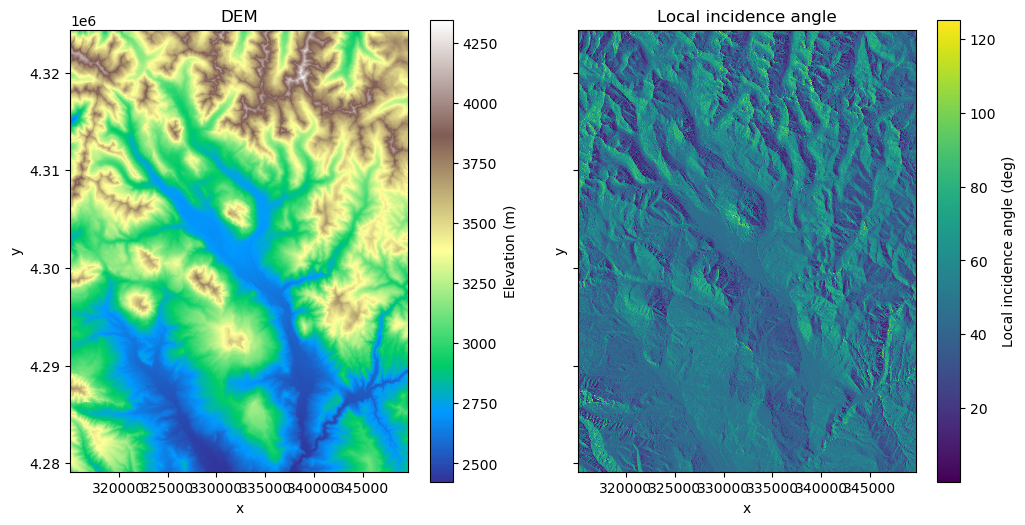

In [22]:
lia = rioxarray.open_rasterio('../data/lia/lia_track019_frame021_10m.tif', masked=True).squeeze(drop=True)
dem = rioxarray.open_rasterio('../data/dem/dem_10m_fullbasin.tif', masked=True).squeeze(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)
dem.plot(ax=axes[0], cmap='terrain', cbar_kwargs={'label': 'Elevation (m)'})
lia.plot(ax=axes[1], cmap='viridis', cbar_kwargs={'label': 'Local incidence angle (deg)'})
axes[0].set_title('DEM'); axes[1].set_title('Local incidence angle')
for ax in axes:
    ax.set_aspect('equal')
print(float(lia.min()), float(lia.median()), float(lia.max()))